+# 05 - Other horizons, explanations (XAI) and robustness

**Inputs:** the files from notebooks 02-04. **Helper code:** `src/forecast_utils.py`, `src/modelling.py`.

## Why this notebook
Notebook 04 answered the main question for **one week ahead**: adding sentiment or delay did **not** improve the forecast (all 95% intervals contained 0, with a tendency for the extra variables to make things slightly worse). Before concluding, a serious study must check that this is **not an artefact of one choice**. Three checks:

| Part | Question | Tool |
|---|---|---|
| **A. Other horizons** | Does sentiment help at 2 or 4 weeks ahead? (It is a *slow* signal, so a longer horizon is a fair test.) | same experiment with `h = 2` and `h = 4` |
| **B. Explanations (XAI)** | Does the model actually **use** sentiment? Does it add something *beyond past sales*? | built-in importance, **permutation importance (PFI)**, **SHAP** |
| **C. Robustness** | Do the conclusions survive other reasonable choices? | without the holiday windows; anchor = last week instead of the 4-week average |

The three explanation tools, in simple words:
- **Gain importance**: how much each feature helped the trees to reduce their errors while *learning*.
- **PFI**: after training, shuffle one feature in the test data and see how much the forecast gets **worse**. If nothing happens, the model did not need it.
- **SHAP**: for each single forecast, how much each feature pushed it up or down (the fair "share of credit").

> Supervisor's remark: XAI should help to see *whether sentiment actually adds predictive value beyond past sales*. That is exactly Part B.

## 1. Setup

In [1]:
import sys, json, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

sys.path.append("../src")
import forecast_utils as fu
import modelling as mdl

pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 160)

PROCESSED = Path("../data/processed")
FIGURES = Path("../outputs/figures")
TABLES = Path("../outputs/tables")

# ----- Parameters (same as notebook 04) -----
N_CONFIGS = 12
SEEDS = (0, 1, 2)
TARGET_MODE = "ratio"

study = json.loads((PROCESSED / "study_config.json").read_text())
cv = json.loads((PROCESSED / "cv_config.json").read_text())
feature_sets = json.loads((PROCESSED / "feature_sets.json").read_text())
STUDY_WEEKS = pd.date_range(study["start_week"], study["end_week"], freq="7D")
model_table = pd.read_csv(PROCESSED / "model_table.csv", parse_dates=["week"])
folds = fu.make_folds(STUDY_WEEKS, cv["first_test"], cv["test_len"], cv["step"])
configs = mdl.sample_configs(N_CONFIGS, seed=0)
BF = fu.BLACK_FRIDAY_WEEKS

# Weeks of the Christmas window (fold 2 of notebook 04 had by far the largest errors for every model)
HOLIDAY = [str(d.date()) for d in pd.date_range("2017-12-11", "2018-01-01", freq="7D")]
print("Folds:", len(folds), "| Holiday target weeks:", HOLIDAY)

Folds: 9 | Holiday target weeks: ['2017-12-11', '2017-12-18', '2017-12-25', '2018-01-01']


## 2. Part A - Longer horizons (2 and 4 weeks ahead)

Same experiment as notebook 04: tuning inside the training data, 3 seeds, 9 windows. For longer horizons, `split_fold()` keeps a gap so that training never uses outcomes that would not yet be known (see notebook 03). The 1-week results are read from the file saved in notebook 04.

In [2]:
preds = {1: pd.read_csv(TABLES / "04_predictions_h1.csv", parse_dates=["target_week"])}
logs = {}
for h in [2, 4]:
    t0 = time.time()
    print(f"Horizon {h} ...")
    preds[h], logs[h], _ = mdl.run_experiment(model_table, folds, h, feature_sets, configs, target_mode=TARGET_MODE, seeds=SEEDS)
    preds[h].to_csv(TABLES / f"05_predictions_h{h}.csv", index=False)
    print(f"  done in {(time.time() - t0) / 60:.1f} min")

base = pd.concat([fu.baseline_predictions(model_table, folds, h, col, name)
                  for h in [1, 2, 4] for col, name in [("orders_l0", "naive_last_week"), ("orders_roll4", "moving_avg_4w")]],
                 ignore_index=True)
allp = pd.concat([base] + list(preds.values()), ignore_index=True)
allp.to_csv(TABLES / "05_all_predictions.csv", index=False)

Horizon 2 ...
  fold 1/9 done (horizon 2, 444 training rows)
  fold 2/9 done (horizon 2, 492 training rows)
  fold 3/9 done (horizon 2, 540 training rows)
  fold 4/9 done (horizon 2, 588 training rows)
  fold 5/9 done (horizon 2, 636 training rows)
  fold 6/9 done (horizon 2, 684 training rows)
  fold 7/9 done (horizon 2, 732 training rows)
  fold 8/9 done (horizon 2, 780 training rows)
  fold 9/9 done (horizon 2, 828 training rows)
  done in 3.0 min
Horizon 4 ...
  fold 1/9 done (horizon 4, 396 training rows)
  fold 2/9 done (horizon 4, 444 training rows)
  fold 3/9 done (horizon 4, 492 training rows)
  fold 4/9 done (horizon 4, 540 training rows)
  fold 5/9 done (horizon 4, 588 training rows)
  fold 6/9 done (horizon 4, 636 training rows)
  fold 7/9 done (horizon 4, 684 training rows)
  fold 8/9 done (horizon 4, 732 training rows)
  fold 9/9 done (horizon 4, 780 training rows)
  done in 2.3 min


In [3]:
order = ["naive_last_week", "moving_avg_4w", "XGB-A", "XGB-B", "XGB-C", "XGB-D"]
fs = fu.score_folds(allp, exclude_target_weeks=BF)
tab = fu.overall_table(fs)
for metric in ["MAE", "RMSE", "WAPE"]:
    print(f"{metric}  (mean over categories, then mean across the 9 windows; Black Friday week excluded)")
    display(tab.pivot(index="model", columns="horizon", values=metric).loc[order].round(3 if metric == "WAPE" else 1))
tab.to_csv(TABLES / "05_overall_by_horizon.csv", index=False)

MAE  (mean over categories, then mean across the 9 windows; Black Friday week excluded)


horizon,1,2,4
model,,,
naive_last_week,19.6,27.4,32.0
moving_avg_4w,22.5,26.0,27.0
XGB-A,20.4,29.0,30.1
XGB-B,21.1,29.2,30.5
XGB-C,21.4,28.7,32.0
XGB-D,21.6,28.8,31.5


RMSE  (mean over categories, then mean across the 9 windows; Black Friday week excluded)


horizon,1,2,4
model,,,
naive_last_week,23.7,32.4,37.4
moving_avg_4w,26.0,30.1,30.9
XGB-A,23.9,33.5,34.1
XGB-B,25.0,33.4,34.6
XGB-C,25.6,32.9,36.4
XGB-D,25.6,33.1,35.7


WAPE  (mean over categories, then mean across the 9 windows; Black Friday week excluded)


horizon,1,2,4
model,,,
naive_last_week,0.240,0.327,0.404
moving_avg_4w,0.277,0.322,0.346
XGB-A,0.247,0.351,0.396
XGB-B,0.259,0.356,0.403
XGB-C,0.271,0.359,0.426
XGB-D,0.271,0.358,0.417


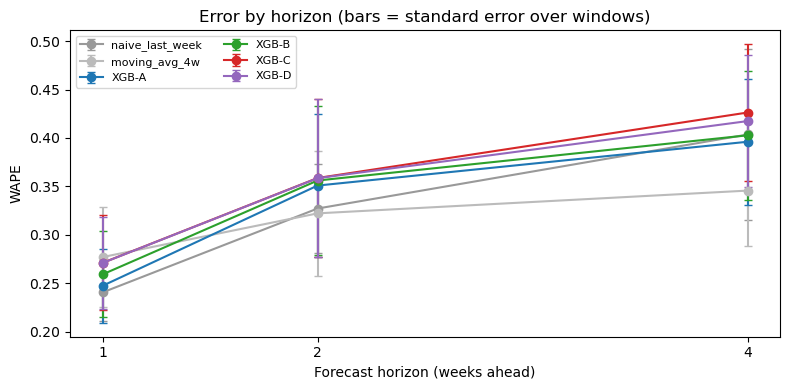

In [4]:
# Does the error grow with the horizon? Mean WAPE with spread across windows
fig, ax = plt.subplots(figsize=(8, 4))
for m, c in zip(order, ["#999999", "#bbbbbb", "#1f77b4", "#2ca02c", "#d62728", "#9467bd"]):
    q = tab[tab["model"] == m].sort_values("horizon")
    ax.errorbar(q["horizon"], q["WAPE"], yerr=q["WAPE_sd"] / 3, marker="o", label=m, color=c, capsize=3)
ax.set_xticks([1, 2, 4]); ax.set_xlabel("Forecast horizon (weeks ahead)"); ax.set_ylabel("WAPE")
ax.set_title("Error by horizon (bars = standard error over windows)"); ax.legend(ncol=2, fontsize=8)
plt.tight_layout(); plt.savefig(FIGURES / "05_wape_by_horizon.png", dpi=150); plt.show()

## 3. The evidence table: does the extra information help?

For every horizon and every pair we report the **change in WAPE** (negative = the extra information helps) with its **95% bootstrap interval**. Verdict rule: interval fully below 0 -> *helps*; fully above 0 -> *hurts*; otherwise *no clear difference*.

In [5]:
def evidence(preds_df, prefix, h, label, exclude):
    rows = []
    for extra, name in [("B", "+ sentiment"), ("C", "+ delay"), ("D", "+ both")]:
        r = fu.paired_bootstrap(preds_df, f"{prefix}A", f"{prefix}{extra}", h, n_boot=2000, seed=0, exclude_target_weeks=exclude)
        rows.append({"setting": label, "comparison": f"A {name}", "diff_wape": r["diff_wape"],
                     "ci_low": r["ci_low"], "ci_high": r["ci_high"]})
    return rows

ev = []
for h in [1, 2, 4]:
    ev += evidence(allp, "XGB-", h, f"h={h}", BF)
ev = pd.DataFrame(ev)
ev["verdict"] = np.where(ev["ci_high"] < 0, "helps", np.where(ev["ci_low"] > 0, "hurts", "no clear difference"))
ev_main = ev.copy()
display(ev.round(4))

,setting,comparison,diff_wape,ci_low,ci_high,verdict
0,h=1,A + sentiment,0.0093,-0.0048,0.0279,no clear difference
1,h=1,A + delay,0.0129,-0.0056,0.0369,no clear difference
2,h=1,A + both,0.0148,-0.0031,0.0374,no clear difference
3,h=2,A + sentiment,0.0020,-0.0067,0.0110,no clear difference
4,h=2,A + delay,-0.0035,-0.0175,0.0115,no clear difference
5,h=2,A + both,-0.0025,-0.0164,0.0123,no clear difference
6,h=4,A + sentiment,0.0045,-0.0063,0.0181,no clear difference
7,h=4,A + delay,0.0222,0.0042,0.0442,hurts
8,h=4,A + both,0.0165,0.0005,0.0361,hurts


## 4. Part B - Does the model use sentiment? (explanations at h = 1)

We re-run the one-week experiment keeping the trained models (it gives exactly the same forecasts as notebook 04, because seeds are fixed). Then we explain **models B and D** (the ones containing sentiment) and use **model A** as a control.

Features are grouped into three families:
- **demand**: past orders and the Black Friday flag
- **sentiment**: scores and share of 1-2 star reviews
- **delay**: share of late deliveries and days late

In [6]:
t0 = time.time()
p1, log1, models1 = mdl.run_experiment(model_table, folds, 1, feature_sets, configs, target_mode=TARGET_MODE,
                                       seeds=SEEDS, return_models=True, verbose=False)
print(f"{(time.time() - t0) / 60:.1f} min")

old = preds[1].sort_values(["model", "category", "target_week"])["y_pred"].to_numpy()
new = p1.sort_values(["model", "category", "target_week"])["y_pred"].to_numpy()
print("Same forecasts as notebook 04:", np.allclose(old, new, rtol=1e-4))

A = feature_sets["A"]
groups = {"demand": A + mdl.CALENDAR,
          "sentiment": [f for f in feature_sets["B"] if f not in A],
          "delay": [f for f in feature_sets["C"] if f not in A]}
groups

2.4 min
Same forecasts as notebook 04: True


{'demand': ['orders_l0',
  'orders_l1',
  'orders_l2',
  'orders_l3',
  'orders_roll4',
  'orders_ratio',
  'target_is_black_friday'],
 'sentiment': ['sent_l0',
  'sent_l1',
  'sent_l2',
  'sent_l3',
  'sent_roll4',
  'neg_l0',
  'neg_roll4'],
 'delay': ['late_l0',
  'late_l1',
  'late_l2',
  'late_l3',
  'late_roll4',
  'latedays_roll4']}

### 4.1 Gain importance (built into XGBoost)
Share of the total "learning gain" given to each feature. It describes what the model used **during training**, so it can overstate noisy features. We therefore check with PFI and SHAP.

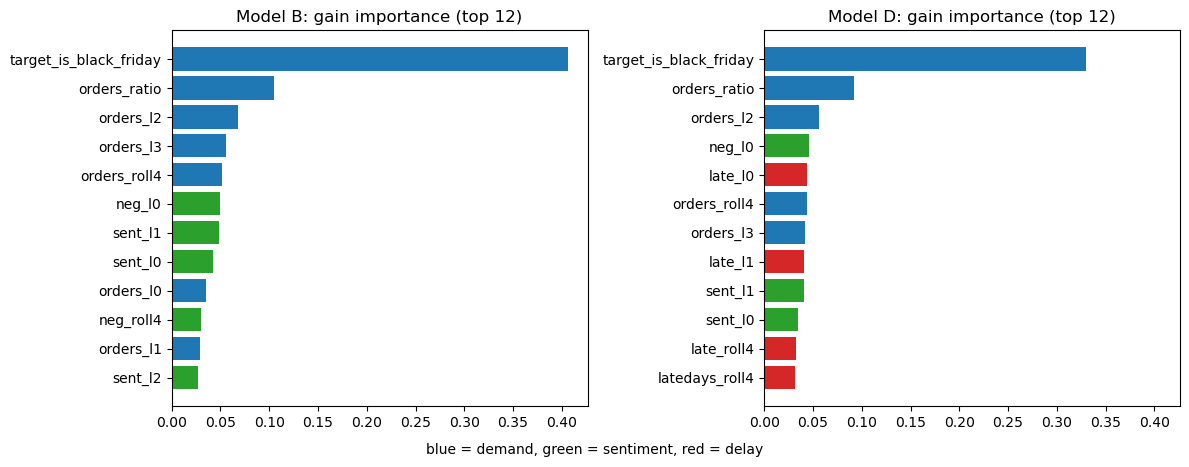

Model B - share of gain by family: {'demand': np.float64(0.751), 'sentiment': np.float64(0.249)}
Model D - share of gain by family: {'demand': np.float64(0.615), 'sentiment': np.float64(0.197), 'delay': np.float64(0.187)}


In [7]:
gain = {k: mdl.gain_importance(models1, k) for k in ["B", "D"]}
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), sharex=True)
for ax, k in zip(axes, ["B", "D"]):
    g = gain[k].head(12)[::-1]
    colors = ["#2ca02c" if f in groups["sentiment"] else "#d62728" if f in groups["delay"] else "#1f77b4" for f in g.index]
    ax.barh(g.index, g.values, color=colors)
    ax.set_title(f"Model {k}: gain importance (top 12)")
fig.text(0.5, -0.02, "blue = demand, green = sentiment, red = delay", ha="center")
plt.tight_layout(); plt.savefig(FIGURES / "05_gain_importance.png", dpi=150, bbox_inches="tight"); plt.show()

for k in ["B", "D"]:
    share = {g: gain[k][[f for f in cols if f in gain[k].index]].sum() for g, cols in groups.items()}
    print(f"Model {k} - share of gain by family:", {g: round(v, 3) for g, v in share.items() if v > 0})

### 4.2 Permutation importance (PFI): what happens to the error if we scramble a family?
On the **test windows**, we shuffle all features of a family together (20 times) and measure the **increase in WAPE**.
- **Clearly positive** -> the model relies on that information and it helps its forecasts.
- **About 0** -> the model ignores it.
- **Negative** -> scrambling it makes forecasts *better*: the feature was adding noise (a sign of overfitting).

The bars show the average over the 9 windows, with the spread.

feature,delay,demand,sentiment
model,,,
A,NaN,0.2680,NaN
B,NaN,0.2738,-0.0010
C,0.0028,0.2762,NaN
D,0.0001,0.2775,-0.0019


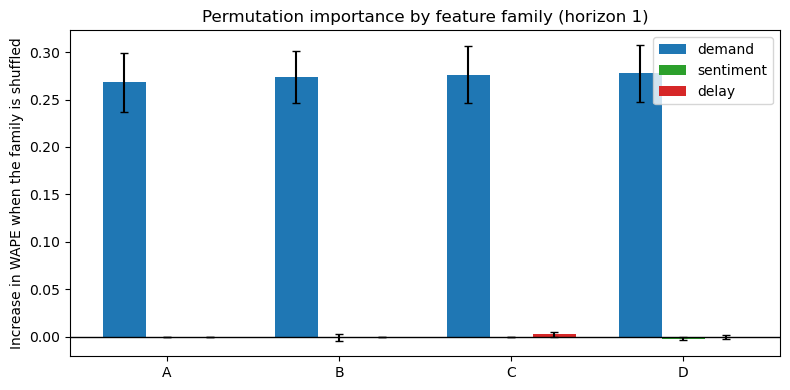

In [8]:
pfi_group = pd.concat([mdl.permutation_importance(models1, k, 1, groups=groups).assign(model=k) for k in ["A", "B", "C", "D"]])
s = pfi_group.groupby(["model", "feature"])["increase_wape"].agg(["mean", "std"]).reset_index()
s.to_csv(TABLES / "05_pfi_groups_h1.csv", index=False)
display(s.pivot(index="model", columns="feature", values="mean").round(4))

fig, ax = plt.subplots(figsize=(8, 4))
w = 0.25
for i, g in enumerate(["demand", "sentiment", "delay"]):
    q = s[s["feature"] == g].set_index("model").reindex(["A", "B", "C", "D"])
    ax.bar(np.arange(4) + (i - 1) * w, q["mean"].fillna(0), w, yerr=q["std"].fillna(0) / 3, capsize=3, label=g,
           color=["#1f77b4", "#2ca02c", "#d62728"][i])
ax.axhline(0, color="black", lw=1)
ax.set_xticks(range(4)); ax.set_xticklabels(["A", "B", "C", "D"])
ax.set_ylabel("Increase in WAPE when the family is shuffled")
ax.set_title("Permutation importance by feature family (horizon 1)")
ax.legend(); plt.tight_layout(); plt.savefig(FIGURES / "05_pfi_groups_h1.png", dpi=150); plt.show()

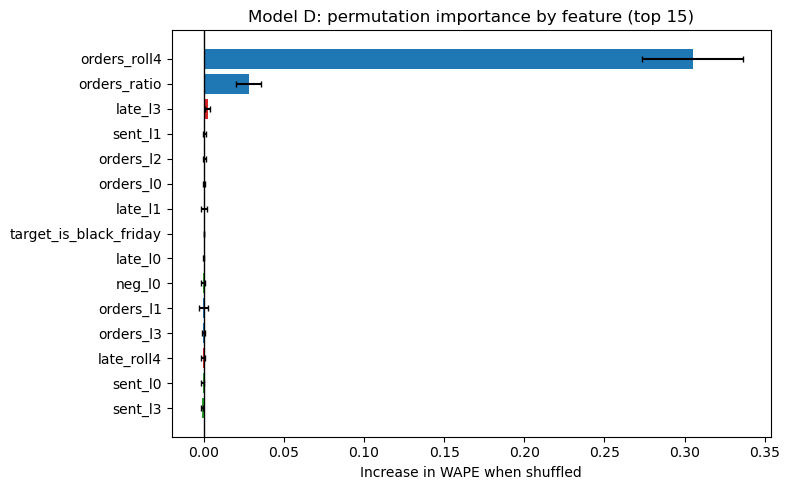

In [9]:
# Feature level, model D (every feature on its own)
pfi_feat = mdl.permutation_importance(models1, "D", 1)
f = pfi_feat.groupby("feature")["increase_wape"].agg(["mean", "std"]).sort_values("mean", ascending=False)
top = f.head(15)[::-1]
colors = ["#2ca02c" if i in groups["sentiment"] else "#d62728" if i in groups["delay"] else "#1f77b4" for i in top.index]
fig, ax = plt.subplots(figsize=(8, 5))
ax.barh(top.index, top["mean"], xerr=top["std"] / 3, color=colors, capsize=2)
ax.axvline(0, color="black", lw=1)
ax.set_xlabel("Increase in WAPE when shuffled"); ax.set_title("Model D: permutation importance by feature (top 15)")
plt.tight_layout(); plt.savefig(FIGURES / "05_pfi_features_D.png", dpi=150); plt.show()
f.round(4).to_csv(TABLES / "05_pfi_features_D_h1.csv")

### 4.3 SHAP: how much does each feature push the forecasts?
For every test forecast, SHAP splits the prediction into the contribution of each feature (here in units of the predicted *ratio*, so 0.05 = 5% more or less than the anchor). We average the **absolute** contributions: it tells how strongly a feature moves forecasts, up or down.

Model D - share of total mean |SHAP| by family: {'demand': np.float32(0.506), 'sentiment': np.float32(0.207), 'delay': np.float32(0.287)}


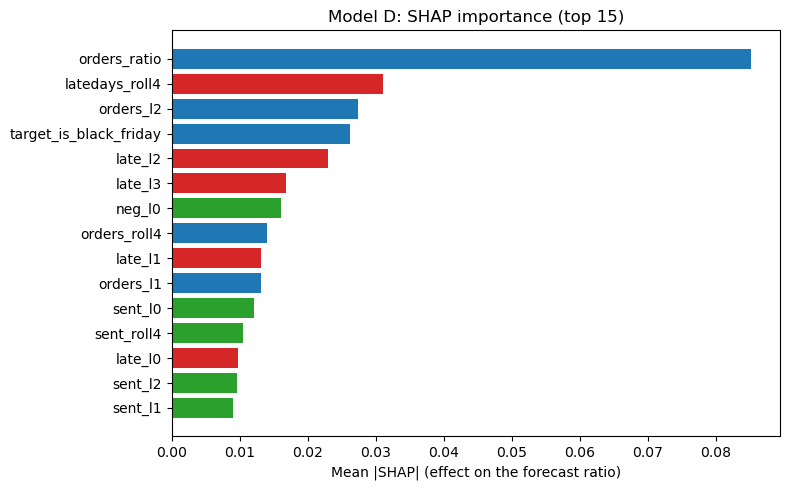

In [10]:
sv, xv = mdl.shap_values(models1, "D", 1)
imp = sv.abs().mean().sort_values(ascending=False)
share = {g: imp[[c for c in cols if c in imp.index]].sum() / imp.sum() for g, cols in groups.items()}
print("Model D - share of total mean |SHAP| by family:", {g: round(v, 3) for g, v in share.items()})

top = imp.head(15)[::-1]
colors = ["#2ca02c" if i in groups["sentiment"] else "#d62728" if i in groups["delay"] else "#1f77b4" for i in top.index]
fig, ax = plt.subplots(figsize=(8, 5))
ax.barh(top.index, top.values, color=colors)
ax.set_xlabel("Mean |SHAP| (effect on the forecast ratio)"); ax.set_title("Model D: SHAP importance (top 15)")
plt.tight_layout(); plt.savefig(FIGURES / "05_shap_importance_D.png", dpi=150); plt.show()
imp.round(4).to_csv(TABLES / "05_shap_importance_D_h1.csv")

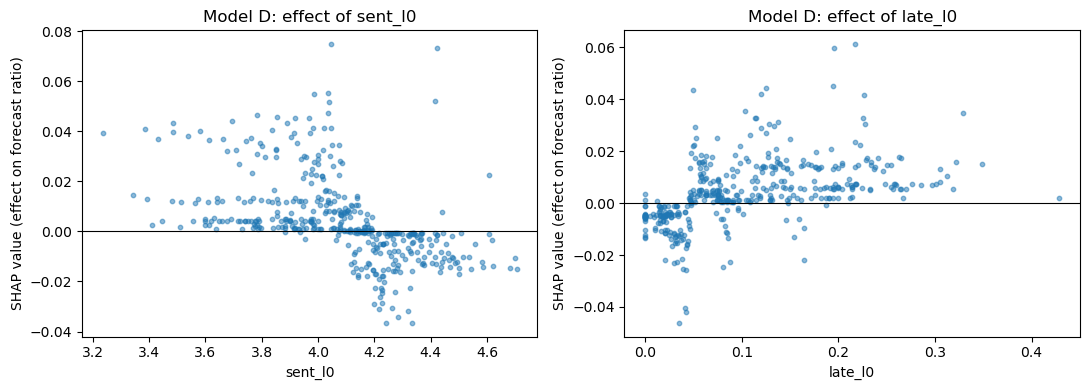

In [11]:
# How does the most important sentiment / delay feature act? (each point = one test forecast)
sent_top = imp[[c for c in groups["sentiment"] if c in imp.index]].index[0]
delay_top = imp[[c for c in groups["delay"] if c in imp.index]].index[0]
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, feat in zip(axes, [sent_top, delay_top]):
    ax.scatter(xv[feat], sv[feat], s=10, alpha=0.5)
    ax.axhline(0, color="black", lw=0.8)
    ax.set_xlabel(feat); ax.set_ylabel("SHAP value (effect on forecast ratio)")
    ax.set_title(f"Model D: effect of {feat}")
plt.tight_layout(); plt.savefig(FIGURES / "05_shap_dependence_D.png", dpi=150); plt.show()

## 5. Part C - Robustness checks (horizon 1)

Two sensible variations. In both, **all four models** are treated the same way, so the comparison stays fair.

1. **Without the holiday windows** (11 Dec 2017 - 1 Jan 2018): in notebook 04, window 2 had by far the largest errors for all models (the fall after Black Friday and the Christmas dip/recovery). Do the conclusions depend on it?
2. **Anchor = last week** instead of the 4-week average: the simple "last week" rule was as good as XGBoost in notebook 04, so we check whether anchoring the ratio on last week's orders helps the models.

In [12]:
# 5.1 without the holiday windows (no new training: same predictions, different scoring)
excl = BF + HOLIDAY
fs_h = fu.score_folds(allp[allp["horizon"] == 1], exclude_target_weeks=excl)
t_h = fu.overall_table(fs_h).set_index("model").loc[order].drop(columns="horizon")
print("Horizon 1, Black Friday AND holiday windows excluded:")
display(t_h.round(3))
ev_h = pd.DataFrame(evidence(allp, "XGB-", 1, "h=1, no holiday", excl))

Horizon 1, Black Friday AND holiday windows excluded:


,MAE,RMSE,WAPE,MAE_sd,RMSE_sd,WAPE_sd
model,,,,,,
naive_last_week,19.217,23.431,0.223,6.891,8.917,0.074
moving_avg_4w,20.161,23.410,0.228,5.025,5.707,0.054
XGB-A,18.988,22.348,0.212,4.581,5.590,0.049
XGB-B,19.234,23.002,0.217,3.974,4.926,0.044
XGB-C,19.188,23.125,0.223,3.893,4.978,0.037
XGB-D,19.488,23.219,0.225,3.919,4.961,0.037


In [13]:
# 5.2 anchor = last week (new training run)
t0 = time.time()
p_lw, _, _ = mdl.run_experiment(model_table, folds, 1, feature_sets, configs, target_mode="ratio", seeds=SEEDS,
                                name_prefix="XGBlw-", anchor="orders_l0", verbose=False)
print(f"{(time.time() - t0) / 60:.1f} min")
p_lw.to_csv(TABLES / "05_predictions_h1_anchor_last_week.csv", index=False)

cmp_ = pd.concat([base[base["horizon"] == 1], preds[1][preds[1]["model"].isin(["XGB-A", "XGB-B"])], p_lw], ignore_index=True)
order_lw = ["naive_last_week", "moving_avg_4w", "XGB-A", "XGB-B", "XGBlw-A", "XGBlw-B", "XGBlw-C", "XGBlw-D"]
t_lw = fu.overall_table(fu.score_folds(cmp_, exclude_target_weeks=BF)).set_index("model").loc[order_lw].drop(columns="horizon")
print("Horizon 1, Black Friday excluded. 'XGBlw' = ratio anchored on last week, 'XGB' = anchored on the 4-week average:")
display(t_lw.round(3))
ev_lw = pd.DataFrame(evidence(cmp_, "XGBlw-", 1, "h=1, anchor last week", BF))

3.5 min
Horizon 1, Black Friday excluded. 'XGBlw' = ratio anchored on last week, 'XGB' = anchored on the 4-week average:


,MAE,RMSE,WAPE,MAE_sd,RMSE_sd,WAPE_sd
model,,,,,,
naive_last_week,19.603,23.736,0.240,6.549,8.391,0.087
moving_avg_4w,22.485,26.032,0.277,8.409,9.504,0.156
XGB-A,20.359,23.929,0.247,5.939,7.059,0.115
XGB-B,21.120,25.030,0.259,6.768,7.633,0.133
XGBlw-A,19.707,23.043,0.237,5.072,5.888,0.094
XGBlw-B,19.738,23.207,0.239,5.122,6.052,0.099
XGBlw-C,20.137,23.753,0.245,5.148,6.240,0.095
XGBlw-D,20.116,23.619,0.245,5.341,6.281,0.101


## 6. The full evidence table (for the report)

,setting,comparison,diff_wape,ci_low,ci_high,verdict
0,h=1,A + sentiment,0.0093,-0.0048,0.0279,no clear difference
1,h=1,A + delay,0.0129,-0.0056,0.0369,no clear difference
2,h=1,A + both,0.0148,-0.0031,0.0374,no clear difference
3,h=2,A + sentiment,0.0020,-0.0067,0.0110,no clear difference
4,h=2,A + delay,-0.0035,-0.0175,0.0115,no clear difference
5,h=2,A + both,-0.0025,-0.0164,0.0123,no clear difference
6,h=4,A + sentiment,0.0045,-0.0063,0.0181,no clear difference
7,h=4,A + delay,0.0222,0.0042,0.0442,hurts
8,h=4,A + both,0.0165,0.0005,0.0361,hurts
9,"h=1, no holiday",A + sentiment,0.0031,-0.0089,0.0195,no clear difference


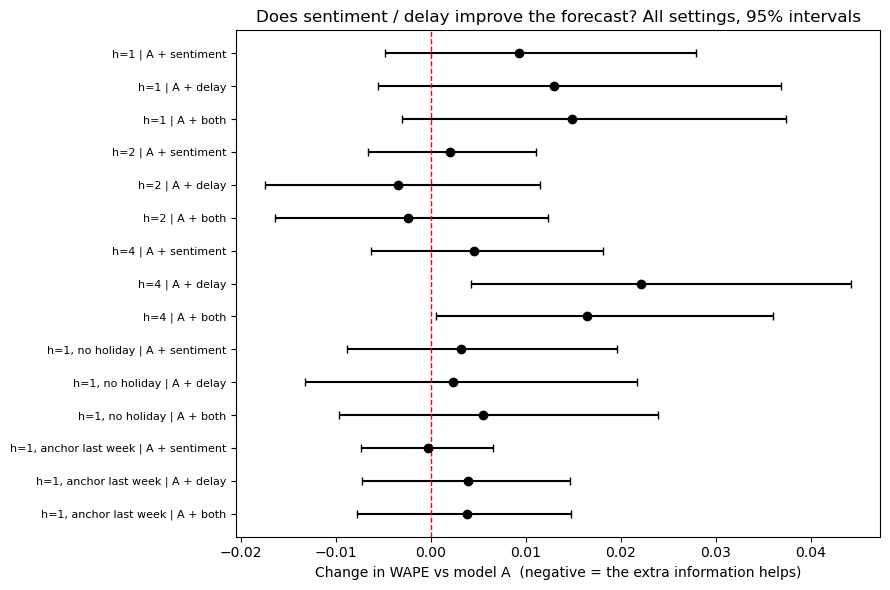

In [14]:
full = pd.concat([ev_main, ev_h, ev_lw], ignore_index=True)
full["verdict"] = np.where(full["ci_high"] < 0, "helps", np.where(full["ci_low"] > 0, "hurts", "no clear difference"))
full.to_csv(TABLES / "05_evidence_table.csv", index=False)
display(full.round(4))

fig, ax = plt.subplots(figsize=(9, 6))
labels = [f"{s} | {c}" for s, c in zip(full["setting"], full["comparison"])]
y = np.arange(len(full))[::-1]
ax.errorbar(full["diff_wape"], y, xerr=[full["diff_wape"] - full["ci_low"], full["ci_high"] - full["diff_wape"]],
            fmt="o", color="black", capsize=3)
ax.axvline(0, color="red", ls="--", lw=1)
ax.set_yticks(y); ax.set_yticklabels(labels, fontsize=8)
ax.set_xlabel("Change in WAPE vs model A  (negative = the extra information helps)")
ax.set_title("Does sentiment / delay improve the forecast? All settings, 95% intervals")
plt.tight_layout(); plt.savefig(FIGURES / "05_evidence_forest.png", dpi=150); plt.show()

## 7. Summary and notes for the report

**How to read the results (fill in with your own numbers and words)**
- *Evidence table / forest plot*: if every interval for "A + sentiment" crosses 0 in all settings, the honest conclusion is **no detectable improvement from sentiment**. If the intervals sit above 0, the extra variables **hurt**.
- *PFI and SHAP*: a family with importance close to 0 (or negative PFI) means the model hardly relies on it. If the sentiment family has a small share of SHAP and about zero PFI, that supports the evidence table: sentiment carries **little information beyond past sales**.
- The delay family is a useful comparison: sentiment scores are partly driven by late deliveries (notebook 03), so if delay is not useful either, the "customer feedback" signal is weak overall.
- Write precisely: say **"no evidence of improvement within the sensitivity of the test"** and give the interval, not "sentiment is useless". The interval tells how large an improvement could still be hidden.

**Limits to state honestly**
- Only 79 weeks and one Black Friday; each test window has 4 weeks, so the confidence intervals are wide.
- A review reaches the business roughly **2 weeks after the purchase** (delivery + answer), so sentiment is a *lagging* rather than a *leading* indicator.
- Sentiment is measured per category per week with about 100 reviews: the weekly average is noisy.
- Events that no past-based model can see (strike in May 2018, Christmas, promotions) dominate the errors.

**What the project contributes even with a null result**
A leakage-safe, reproducible protocol (dates of knowledge, rolling windows, paired bootstrap), and a clear, quantified answer to a question that businesses often assume has a positive answer.

*Suggested commit message:* `Add notebook 05: longer horizons, XAI (gain, PFI, SHAP) and robustness checks`